# Complete PyTorch Image Classification Project

**Start:** Runtime > Change runtime type > GPU. Run the cells in order.

The code uses your existing Colab PyTorch and torchvision. First try one epoch per model by editing `CONFIG` below if you want a short smoke run. Default settings train three models. Optional debugging, transfer-learning and profiling stages are included.

**Save your work:** `/content` is temporary. Download results or set `OUT` to a mounted Google Drive folder before training. The README explains checkpoint resume.

**Learning goal:** understand each training step and interpret your own results. No benchmark numbers are pre-filled. Full GPU training has not been run by the author here.


CIFAR-10: Training, Evaluation, and GPU Performance
Run the cells in order in a Colab GPU runtime. Existing Colab PyTorch and
torchvision are used; this project does not reinstall CUDA or PyTorch.
The default run trains an MLP and two small CNNs. Transfer learning and a
tiny-subset debugging exercise are included as optional experiments.


In [1]:
import copy
import csv
import gc
import json
import random
import time
from contextlib import nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
from tqdm.auto import tqdm

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('/content/cifar10_project_results') if Path('/content').exists() else Path('cifar10_project_results')
DATA = OUT / 'data'
OUT.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'seed': SEED,
    'batch_size': 128,
    'num_workers': 2,
    'mlp_epochs': 3,
    'cnn_epochs': 8,
    'regularized_cnn_epochs': 8,
    'run_tiny_subset': False,
    'run_transfer_learning': False,
    'transfer_head_epochs': 2,
    'transfer_finetune_epochs': 2,
    'run_precision_benchmark': True,
}

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def release_memory():
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

environment = {
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
    'device': str(DEVICE),
    'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    'cuda': torch.version.cuda,
    'config': CONFIG,
}
(OUT / 'environment.json').write_text(json.dumps(environment, indent=2))
print(json.dumps(environment, indent=2))
if DEVICE.type != 'cuda':
    print('CPU detected. Enable a Colab GPU for the full experiment.')


{
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "device": "cuda",
  "gpu": "Tesla T4",
  "cuda": "13.0",
  "config": {
    "seed": 42,
    "batch_size": 128,
    "num_workers": 2,
    "mlp_epochs": 3,
    "cnn_epochs": 8,
    "regularized_cnn_epochs": 8,
    "run_tiny_subset": false,
    "run_transfer_learning": false,
    "transfer_head_epochs": 2,
    "transfer_finetune_epochs": 2,
    "run_precision_benchmark": true
  }
}


1. Data pipeline
Training: 45,000 examples. Validation: 5,000. Official test: 10,000.
We choose configurations using validation, then evaluate the selected model
once on the test set. Random augmentation is applied to training only.
Fixed normalization constants are used; no test statistics are computed.


100%|██████████| 170M/170M [22:26<00:00, 127kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training: 45000 | Validation: 5000


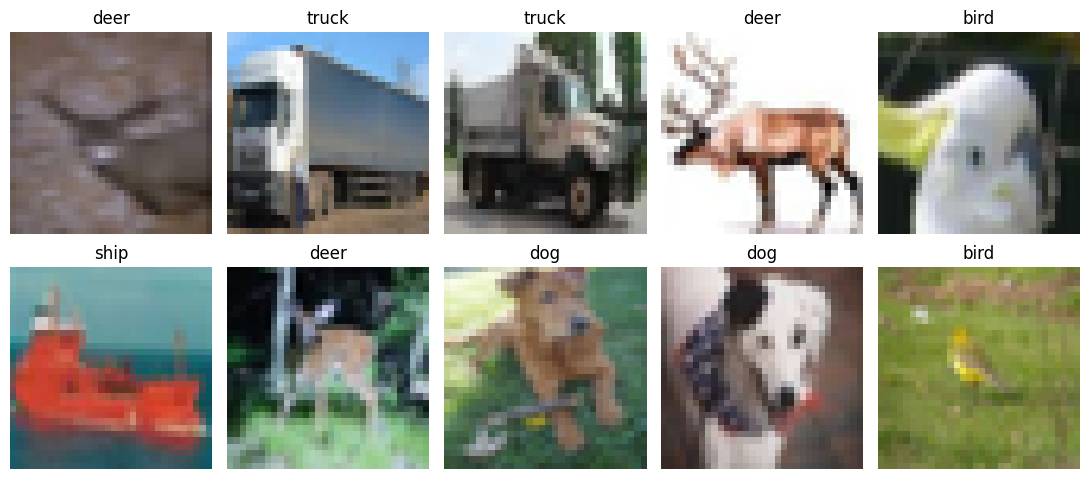

In [2]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

plain_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
augmented_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

plain_dataset = datasets.CIFAR10(DATA, train=True, download=True, transform=plain_transform)
augmented_dataset = datasets.CIFAR10(DATA, train=True, download=False, transform=augmented_transform)
CLASSES = plain_dataset.classes
permutation = torch.randperm(len(plain_dataset), generator=torch.Generator().manual_seed(SEED)).tolist()
TRAIN_IDS, VAL_IDS = permutation[5000:], permutation[:5000]
assert set(TRAIN_IDS).isdisjoint(VAL_IDS)
assert len(TRAIN_IDS) + len(VAL_IDS) == 50000
(OUT / 'split_indices.json').write_text(json.dumps({'train': TRAIN_IDS, 'validation': VAL_IDS}))

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(dataset, shuffle=False, batch_size=None):
    return DataLoader(
        dataset,
        batch_size=batch_size or CONFIG['batch_size'],
        shuffle=shuffle,
        num_workers=CONFIG['num_workers'],
        pin_memory=DEVICE.type == 'cuda',
        worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(SEED),
        persistent_workers=False,
    )

def make_loaders(augment=False):
    train_source = augmented_dataset if augment else plain_dataset
    return (
        make_loader(Subset(train_source, TRAIN_IDS), shuffle=True),
        make_loader(Subset(plain_dataset, VAL_IDS)),
    )

print('Classes:', CLASSES)
print('Training:', len(TRAIN_IDS), '| Validation:', len(VAL_IDS))

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, index in zip(axes.flat, TRAIN_IDS[:10]):
    image, label = plain_dataset[index]
    image = image * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(CLASSES[label])
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT / 'sample_images.png', dpi=150)
plt.show()


2. Models
MLP input: [batch, 3, 32, 32] -> flattened [batch, 3072].
CNN: three convolution/pooling stages, then global average pooling.
Each model returns ten raw logits. CrossEntropyLoss includes log-softmax,
so do not put softmax in the model before this loss.


In [3]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.network(x)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

for constructor in (MLP, SmallCNN):
    check = constructor()
    assert check(torch.zeros(2, 3, 32, 32)).shape == (2, 10)
    print(constructor.__name__, 'parameters:', sum(p.numel() for p in check.parameters()))
del check


MLP parameters: 820874
SmallCNN parameters: 103786


3. Training and evaluation
model.train() enables training behavior. model.eval() switches modules such
as dropout and batch normalization to evaluation behavior. eval() alone does
not disable gradients; inference_mode() does that for validation/testing.


In [4]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None, scaler=None, amp=False, freeze_backbone=False):
    training = optimizer is not None
    model.train(training)
    if training and freeze_backbone:
        model.eval()
        model.fc.train()

    loss_sum = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE, dtype=torch.long)
    count = 0
    amp_enabled = amp and DEVICE.type == 'cuda'
    sync()
    start = time.perf_counter()
    gradient_context = torch.enable_grad() if training else torch.inference_mode()
    with gradient_context:
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            context = torch.autocast('cuda', dtype=torch.float16) if amp_enabled else nullcontext()
            with context:
                logits = model(images)
                loss = criterion(logits, labels)
            if training:
                if amp_enabled:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()
            loss_sum += loss.detach() * labels.size(0)
            correct += (logits.detach().argmax(1) == labels).sum()
            count += labels.size(0)
    sync()
    seconds = time.perf_counter() - start
    return {
        'loss': loss_sum.item() / count,
        'accuracy': correct.item() / count,
        'seconds': seconds,
        'images_per_second': count / seconds,
    }

def fit(model, train_loader, val_loader, name, epochs, lr=1e-3,
        weight_decay=0.0, amp=False, resume=False, freeze_backbone=False):
    folder = OUT / name
    folder.mkdir(exist_ok=True)
    model.to(DEVICE)
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr, weight_decay=weight_decay,
    )
    scaler = torch.amp.GradScaler('cuda', enabled=amp and DEVICE.type == 'cuda')
    history, start_epoch, best_accuracy = [], 0, -1.0
    settings = dict(lr=lr, weight_decay=weight_decay, amp=amp,
                    freeze_backbone=freeze_backbone, batch_size=train_loader.batch_size)
    last_file = folder / 'last.pt'
    if resume and last_file.exists():
        checkpoint = torch.load(last_file, map_location='cpu', weights_only=False)
        if checkpoint['settings'] != settings:
            raise ValueError('Resume settings differ from the saved experiment.')
        model.load_state_dict(checkpoint['model'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        scaler.load_state_dict(checkpoint['scaler'])
        history = checkpoint['history']
        start_epoch = checkpoint['epoch'] + 1
        best_accuracy = checkpoint['best_accuracy']
        random.setstate(checkpoint['python_rng'])
        np.random.set_state(checkpoint['numpy_rng'])
        torch.set_rng_state(checkpoint['torch_rng'])
        if DEVICE.type == 'cuda' and checkpoint['cuda_rng'] is not None:
            torch.cuda.set_rng_state_all(checkpoint['cuda_rng'])
        train_loader.generator.set_state(checkpoint['loader_rng'])
        print(f'Resuming {name} at epoch {start_epoch + 1}')

    for epoch in range(start_epoch, epochs):
        train_metrics = run_epoch(model, train_loader, optimizer, scaler, amp, freeze_backbone)
        val_metrics = run_epoch(model, val_loader, amp=amp)
        history.append({'epoch': epoch + 1, 'train': train_metrics, 'validation': val_metrics})
        if val_metrics['accuracy'] > best_accuracy:
            best_accuracy = val_metrics['accuracy']
            torch.save({'model': model.state_dict(), 'epoch': epoch + 1,
                        'validation_accuracy': best_accuracy}, folder / 'best.pt')
        checkpoint = {
            'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
            'scaler': scaler.state_dict(), 'epoch': epoch, 'history': history,
            'best_accuracy': best_accuracy, 'settings': settings,
            'python_rng': random.getstate(), 'numpy_rng': np.random.get_state(),
            'torch_rng': torch.get_rng_state(),
            'cuda_rng': torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None,
            'loader_rng': train_loader.generator.get_state(),
        }
        temporary = folder / 'last.tmp'
        torch.save(checkpoint, temporary)
        temporary.replace(last_file)
        (folder / 'history.json').write_text(json.dumps(history, indent=2))
        print(f'{name} | epoch {epoch + 1}/{epochs} | '
              f'train loss {train_metrics["loss"]:.3f}, acc {train_metrics["accuracy"]:.1%} | '
              f'val loss {val_metrics["loss"]:.3f}, acc {val_metrics["accuracy"]:.1%} | '
              f'{train_metrics["seconds"]:.1f}s training', flush=True)
    return history, best_accuracy


4. Optional debugging exercise: memorize 64 examples
This is deliberately NOT an evaluation result. Successful memorization helps
check the optimizer, loss, gradient flow and labels. If it fails, investigate
before spending time training the full dataset. Enable in CONFIG above.


In [5]:
if CONFIG['run_tiny_subset']:
    seed_everything(SEED)
    tiny_model = SmallCNN().to(DEVICE)
    tiny_loader = make_loader(Subset(plain_dataset, TRAIN_IDS[:64]), shuffle=True, batch_size=64)
    tiny_optimizer = torch.optim.Adam(tiny_model.parameters(), lr=3e-3)
    for epoch in range(150):
        metrics = run_epoch(tiny_model, tiny_loader, tiny_optimizer)
        if (epoch + 1) % 10 == 0:
            print(f'Tiny subset epoch {epoch + 1}: accuracy={metrics["accuracy"]:.1%}')
        if metrics['accuracy'] >= 0.99:
            print('Tiny-subset memorization check passed.')
            break
    else:
        print('Did not reach 99%. Inspect the learning curve; this is a debugging exercise.')
    del tiny_model, tiny_optimizer, tiny_loader
    release_memory()


5. Controlled experiments
MLP versus CNN changes architecture. CNN versus CNN+augmentation changes
only augmentation. If enabled, the next experiment adds only weight decay.
Fresh seeds/loaders give CNN experiments matching initial weights and sample
order. Do not compare models solely on training accuracy.


In [6]:
EXPERIMENTS = [
    dict(name='mlp', constructor=MLP, augment=False, weight_decay=0.0, epochs=CONFIG['mlp_epochs']),
    dict(name='cnn_baseline', constructor=SmallCNN, augment=False, weight_decay=0.0, epochs=CONFIG['cnn_epochs']),
    dict(name='cnn_augmentation', constructor=SmallCNN, augment=True, weight_decay=0.0, epochs=CONFIG['regularized_cnn_epochs']),
]
summaries = []
for experiment in EXPERIMENTS:
    seed_everything(SEED)
    train_loader, val_loader = make_loaders(experiment['augment'])
    current_model = experiment['constructor']()
    history, best = fit(
        current_model, train_loader, val_loader,
        name=experiment['name'], epochs=experiment['epochs'],
        weight_decay=experiment['weight_decay'], resume=True,
    )
    summaries.append({
        'name': experiment['name'], 'best_validation_accuracy': best,
        'epochs_completed': len(history),
        'training_seconds': sum(h['train']['seconds'] for h in history),
        'augmentation': experiment['augment'], 'weight_decay': experiment['weight_decay'],
    })
    del current_model, train_loader, val_loader
    release_memory()


mlp | epoch 1/3 | train loss 1.671, acc 40.6% | val loss 1.511, acc 47.6% | 10.0s training
mlp | epoch 2/3 | train loss 1.453, acc 48.9% | val loss 1.437, acc 50.2% | 9.7s training
mlp | epoch 3/3 | train loss 1.347, acc 52.6% | val loss 1.434, acc 50.8% | 9.4s training
cnn_baseline | epoch 1/8 | train loss 1.762, acc 34.5% | val loss 1.523, acc 44.4% | 11.9s training
cnn_baseline | epoch 2/8 | train loss 1.404, acc 49.4% | val loss 1.378, acc 50.3% | 10.0s training
cnn_baseline | epoch 3/8 | train loss 1.221, acc 56.5% | val loss 1.155, acc 59.0% | 10.0s training
cnn_baseline | epoch 4/8 | train loss 1.113, acc 60.7% | val loss 1.106, acc 60.9% | 10.1s training
cnn_baseline | epoch 5/8 | train loss 1.022, acc 64.1% | val loss 1.001, acc 64.8% | 10.0s training
cnn_baseline | epoch 6/8 | train loss 0.962, acc 66.0% | val loss 0.964, acc 65.2% | 9.9s training
cnn_baseline | epoch 7/8 | train loss 0.917, acc 67.9% | val loss 0.911, acc 67.3% | 10.1s training
cnn_baseline | epoch 8/8 | tra

6. Optional transfer learning
Uses ImageNet-pretrained ResNet-18 at 224x224 with ImageNet normalization.
First train its new classifier, then fine-tune all layers at a lower learning
rate. This is a different recipe/resolution; not an architecture-only ablation.
It downloads pretrained weights and costs more compute. Enable in CONFIG.


In [7]:
if CONFIG['run_transfer_learning']:
    seed_everything(SEED)
    weights = models.ResNet18_Weights.DEFAULT
    transfer_eval = weights.transforms()
    transfer_train = transforms.Compose([
        transforms.Resize(256), transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(), transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ])
    transfer_train_dataset = datasets.CIFAR10(DATA, train=True, transform=transfer_train)
    transfer_val_dataset = datasets.CIFAR10(DATA, train=True, transform=transfer_eval)
    transfer_train_loader = make_loader(Subset(transfer_train_dataset, TRAIN_IDS), True, batch_size=64)
    transfer_val_loader = make_loader(Subset(transfer_val_dataset, VAL_IDS), batch_size=64)
    transfer_model = models.resnet18(weights=weights)
    for parameter in transfer_model.parameters():
        parameter.requires_grad = False
    transfer_model.fc = nn.Linear(transfer_model.fc.in_features, 10)
    head_history, head_best = fit(
        transfer_model, transfer_train_loader, transfer_val_loader,
        'resnet18_head', CONFIG['transfer_head_epochs'],
        freeze_backbone=True, resume=True,
    )
    transfer_model.load_state_dict(torch.load(OUT/'resnet18_head/best.pt', map_location='cpu', weights_only=True)['model'])
    for parameter in transfer_model.parameters():
        parameter.requires_grad = True
    fine_history, fine_best = fit(
        transfer_model, transfer_train_loader, transfer_val_loader,
        'resnet18_finetuned', CONFIG['transfer_finetune_epochs'], lr=1e-4,
        weight_decay=1e-4, resume=True,
    )
    for name, history, best in [('resnet18_head', head_history, head_best), ('resnet18_finetuned', fine_history, fine_best)]:
        summaries.append({'name': name, 'best_validation_accuracy': best,
                          'epochs_completed': len(history),
                          'training_seconds': sum(h['train']['seconds'] for h in history),
                          'augmentation': True, 'weight_decay': 0.0 if name.endswith('head') else 1e-4})
    del transfer_model, transfer_train_loader, transfer_val_loader
    release_memory()


7. Compare learning curves and select by validation accuracy
The official test set has not yet been evaluated. Keep it out of model and
hyperparameter selection. Training accuracy with augmentation is measured on
transformed images, so it is not directly identical to validation conditions.


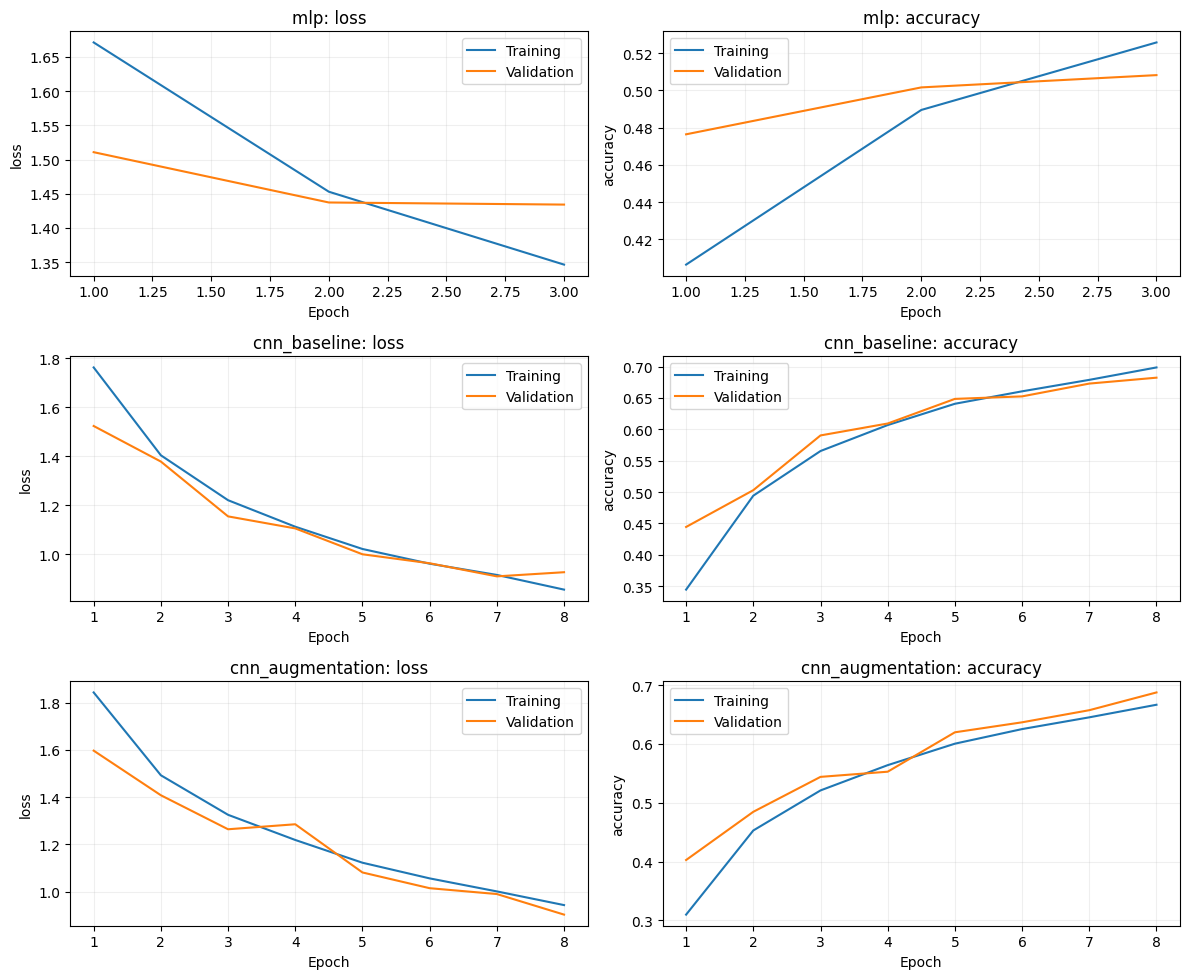

[
  {
    "name": "mlp",
    "best_validation_accuracy": 0.5082,
    "epochs_completed": 3,
    "training_seconds": 29.004829727000015,
    "augmentation": false,
    "weight_decay": 0.0
  },
  {
    "name": "cnn_baseline",
    "best_validation_accuracy": 0.6822,
    "epochs_completed": 8,
    "training_seconds": 82.00057588699974,
    "augmentation": false,
    "weight_decay": 0.0
  },
  {
    "name": "cnn_augmentation",
    "best_validation_accuracy": 0.6876,
    "epochs_completed": 8,
    "training_seconds": 115.6339032449996,
    "augmentation": true,
    "weight_decay": 0.0
  }
]
Selected using validation only: cnn_augmentation


In [8]:
(OUT / 'experiment_summary.json').write_text(json.dumps(summaries, indent=2))
with (OUT / 'experiment_summary.csv').open('w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(summaries[0]))
    writer.writeheader()
    writer.writerows(summaries)
fig, axes = plt.subplots(len(summaries), 2, figsize=(12, 3.3 * len(summaries)), squeeze=False)
for row, summary in enumerate(summaries):
    history = json.loads((OUT / summary['name'] / 'history.json').read_text())
    epochs = [h['epoch'] for h in history]
    for column, metric in enumerate(['loss', 'accuracy']):
        ax = axes[row, column]
        ax.plot(epochs, [h['train'][metric] for h in history], label='Training')
        ax.plot(epochs, [h['validation'][metric] for h in history], label='Validation')
        ax.set(title=f'{summary["name"]}: {metric}', xlabel='Epoch', ylabel=metric)
        ax.legend()
        ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / 'learning_curves.png', dpi=150)
plt.show()
print(json.dumps(summaries, indent=2))
winner = max(summaries, key=lambda row: row['best_validation_accuracy'])['name']
print('Selected using validation only:', winner)


8. Final test evaluation and failure analysis
Run this after deciding your experiments. If you tune after inspecting test
results, the test set is no longer an untouched final evaluation.


Final test evaluation:   0%|          | 0/157 [00:00<?, ?it/s]

{
  "selected_model": "cnn_augmentation",
  "checkpoint_epoch": 8,
  "test_accuracy": 0.6794,
  "test_loss": 0.9114867847442627,
  "macro_f1": 0.6783219575881958,
  "per_class": {
    "airplane": {
      "precision": 0.7520467638969421,
      "recall": 0.6430000066757202,
      "f1": 0.6932615041732788
    },
    "automobile": {
      "precision": 0.8497354388237,
      "recall": 0.8029999732971191,
      "f1": 0.8257068991661072
    },
    "bird": {
      "precision": 0.5519999861717224,
      "recall": 0.5519999861717224,
      "f1": 0.5519999861717224
    },
    "cat": {
      "precision": 0.5060483813285828,
      "recall": 0.5019999742507935,
      "f1": 0.504016101360321
    },
    "deer": {
      "precision": 0.5942307710647583,
      "recall": 0.6179999709129333,
      "f1": 0.6058823466300964
    },
    "dog": {
      "precision": 0.6633166074752808,
      "recall": 0.527999997138977,
      "f1": 0.5879732966423035
    },
    "frog": {
      "precision": 0.7145540118217468,
  

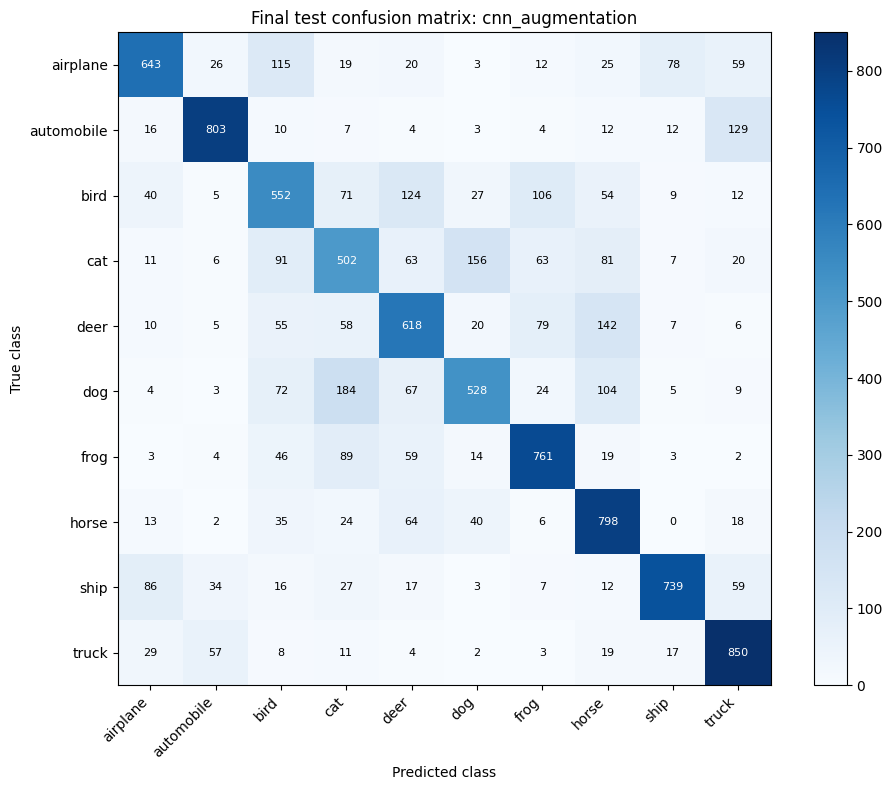

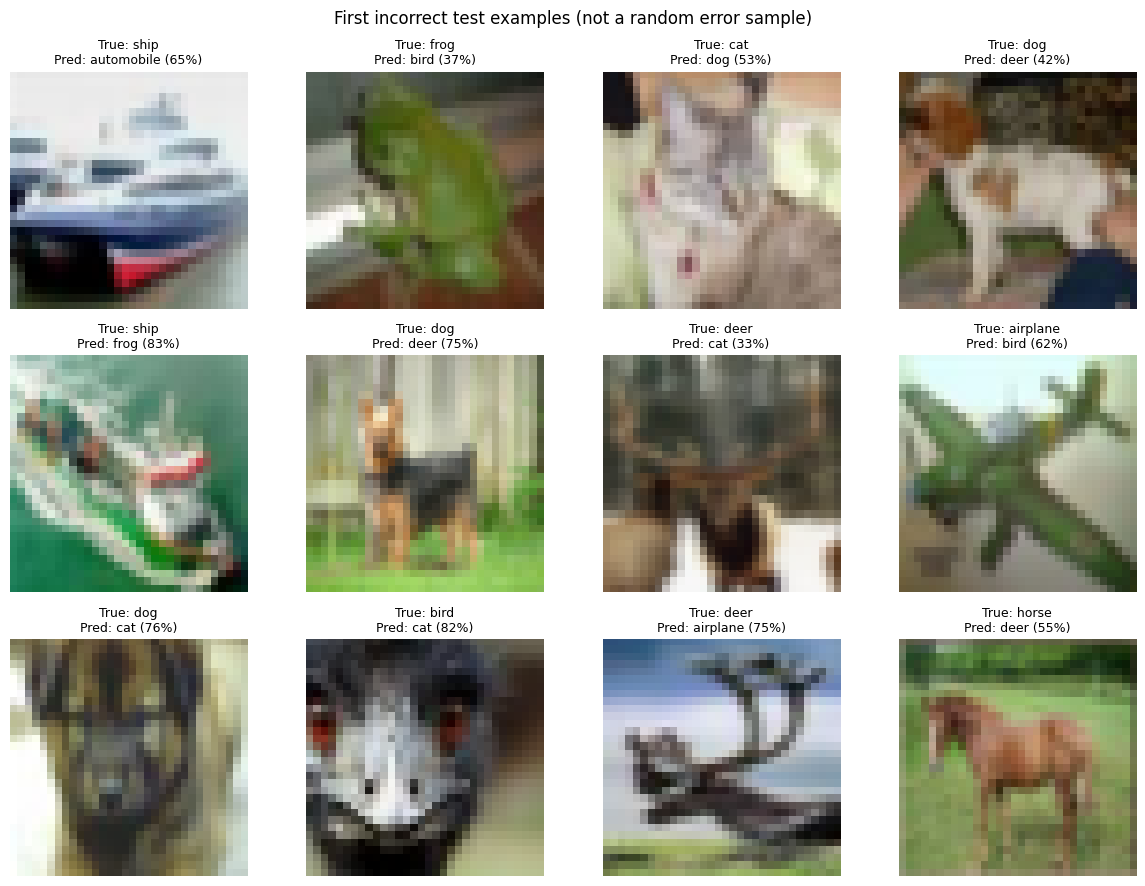

In [9]:
if winner.startswith('resnet18'):
    selected_model = models.resnet18(weights=None)
    selected_model.fc = nn.Linear(selected_model.fc.in_features, 10)
    test_transform = models.ResNet18_Weights.DEFAULT.transforms()
else:
    selected_model = MLP() if winner == 'mlp' else SmallCNN()
    test_transform = plain_transform
best_checkpoint = torch.load(OUT / winner / 'best.pt', map_location='cpu', weights_only=True)
selected_model.load_state_dict(best_checkpoint['model'])
selected_model.to(DEVICE).eval()
test_dataset = datasets.CIFAR10(DATA, train=False, download=True, transform=test_transform)
test_loader = make_loader(test_dataset, batch_size=64)
confusion = torch.zeros(10, 10, dtype=torch.long)
wrong_examples = []
test_loss_sum = 0.0
with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc='Final test evaluation'):
        logits = selected_model(images.to(DEVICE, non_blocking=True))
        test_loss_sum += criterion(logits, labels.to(DEVICE)).item() * labels.size(0)
        probabilities = logits.softmax(1).cpu()
        confidence, predictions = probabilities.max(1)
        confusion += torch.bincount(10 * labels + predictions, minlength=100).reshape(10, 10)
        for i in (predictions != labels).nonzero(as_tuple=True)[0].tolist():
            if len(wrong_examples) < 12:
                wrong_examples.append((images[i].clone(), labels[i].item(), predictions[i].item(), confidence[i].item()))

true_positive = confusion.diag().float()
precision = true_positive / confusion.sum(0).clamp_min(1)
recall = true_positive / confusion.sum(1).clamp_min(1)
f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
test_report = {
    'selected_model': winner,
    'checkpoint_epoch': best_checkpoint['epoch'],
    'test_accuracy': true_positive.sum().item() / confusion.sum().item(),
    'test_loss': test_loss_sum / len(test_dataset),
    'macro_f1': f1.mean().item(),
    'per_class': {name: {'precision': precision[i].item(), 'recall': recall[i].item(), 'f1': f1[i].item()} for i, name in enumerate(CLASSES)},
    'confusion_matrix': confusion.tolist(),
}
(OUT / 'final_test_report.json').write_text(json.dumps(test_report, indent=2))
print(json.dumps(test_report, indent=2))
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(confusion.numpy(), cmap='Blues')
fig.colorbar(image, ax=ax)
ax.set(xticks=range(10), yticks=range(10), xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel='Predicted class', ylabel='True class', title=f'Final test confusion matrix: {winner}')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(confusion[i, j]), ha='center', va='center', fontsize=8,
                color='white' if confusion[i, j] > confusion.max() / 2 else 'black')
plt.tight_layout()
plt.savefig(OUT / 'confusion_matrix.png', dpi=150)
plt.show()

mean, std = (MEAN, STD) if not winner.startswith('resnet18') else ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax in axes.flat:
    ax.axis('off')
for ax, (image, actual, predicted, confidence) in zip(axes.flat, wrong_examples):
    restored = image * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]
    ax.imshow(restored.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f'True: {CLASSES[actual]}\nPred: {CLASSES[predicted]} ({confidence:.0%})', fontsize=9)
plt.suptitle('First incorrect test examples (not a random error sample)')
plt.tight_layout()
plt.savefig(OUT / 'incorrect_predictions.png', dpi=150)
plt.show()


torch.save({'model': selected_model.state_dict(), 'architecture': winner,
            'classes': CLASSES, 'mean': mean, 'std': std,
            'input_size': 224 if winner.startswith('resnet18') else 32}, OUT / 'inference_model.pt')
del selected_model, test_loader
release_memory()


9. FP32 versus mixed-precision TRAINING microbenchmark
Fixed synthetic GPU-resident batch, same initial weights and batch size,
fresh optimizer each repeat, warm-up, synchronized timing. This isolates
training-step performance: it excludes loading, augmentation and transfers.
It does not measure full-training accuracy or guarantee AMP is faster.


In [10]:
def precision_microbenchmark(batch_size=128, warmup=10, steps=30, repeats=3):
    if DEVICE.type != 'cuda':
        print('Precision microbenchmark requires a CUDA GPU; skipped.')
        return []
    seed_everything(SEED)
    initial = copy.deepcopy(SmallCNN().state_dict())
    images = torch.randn(batch_size, 3, 32, 32, device=DEVICE)
    labels = torch.randint(0, 10, (batch_size,), device=DEVICE)
    rows = []
    for use_amp in [False, True]:
        for repeat in range(repeats):
            network = SmallCNN().to(DEVICE)
            network.load_state_dict(initial)
            network.train()
            optimizer = torch.optim.Adam(network.parameters(), lr=1e-3)
            scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

            def step():
                optimizer.zero_grad(set_to_none=True)
                context = torch.autocast('cuda', dtype=torch.float16) if use_amp else nullcontext()
                with context:
                    loss = criterion(network(images), labels)
                if use_amp:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

            for _ in range(warmup):
                step()
            sync()
            torch.cuda.reset_peak_memory_stats()
            start = time.perf_counter()
            for _ in range(steps):
                step()
            sync()
            elapsed = time.perf_counter() - start
            rows.append({'precision': 'AMP_FP16' if use_amp else 'FP32',
                         'repeat': repeat + 1, 'batch_size': batch_size,
                         'steps': steps, 'seconds': elapsed,
                         'images_per_second': steps * batch_size / elapsed,
                         'peak_allocated_memory_gib': torch.cuda.max_memory_allocated() / 2**30})
            print(rows[-1])
            del network, optimizer, scaler, step
            release_memory()
    (OUT / 'precision_microbenchmark.json').write_text(json.dumps(rows, indent=2))
    for precision in ['FP32', 'AMP_FP16']:
        speeds = [row['images_per_second'] for row in rows if row['precision'] == precision]
        print(f'{precision}: median {np.median(speeds):.1f} training images/s')
    return rows

if CONFIG['run_precision_benchmark']:
    precision_results = precision_microbenchmark()


{'precision': 'FP32', 'repeat': 1, 'batch_size': 128, 'steps': 30, 'seconds': 0.47330021200014016, 'images_per_second': 8113.243777712195, 'peak_allocated_memory_gib': 0.34017419815063477}
{'precision': 'FP32', 'repeat': 2, 'batch_size': 128, 'steps': 30, 'seconds': 0.46203677099993, 'images_per_second': 8311.026829508732, 'peak_allocated_memory_gib': 0.34017419815063477}
{'precision': 'FP32', 'repeat': 3, 'batch_size': 128, 'steps': 30, 'seconds': 0.46369408200007456, 'images_per_second': 8281.321994528675, 'peak_allocated_memory_gib': 0.34017419815063477}
{'precision': 'AMP_FP16', 'repeat': 1, 'batch_size': 128, 'steps': 30, 'seconds': 0.14668727799971748, 'images_per_second': 26178.1393203533, 'peak_allocated_memory_gib': 0.062415122985839844}
{'precision': 'AMP_FP16', 'repeat': 2, 'batch_size': 128, 'steps': 30, 'seconds': 0.14593034199970134, 'images_per_second': 26313.92448876642, 'peak_allocated_memory_gib': 0.062415122985839844}
{'precision': 'AMP_FP16', 'repeat': 3, 'batch_siz

10. Optional profiling
Run profile_training_step() to export a trace for a fresh small CNN.
Profiler measurements have overhead; use the unprofiled benchmark for speed.


In [11]:
def profile_training_step():
    seed_everything(SEED)
    network = SmallCNN().to(DEVICE).train()
    optimizer = torch.optim.Adam(network.parameters(), lr=1e-3)
    images = torch.randn(128, 3, 32, 32, device=DEVICE)
    labels = torch.randint(0, 10, (128,), device=DEVICE)
    for _ in range(5):
        optimizer.zero_grad(set_to_none=True)
        criterion(network(images), labels).backward()
        optimizer.step()
    sync()
    activities = [torch.profiler.ProfilerActivity.CPU]
    if DEVICE.type == 'cuda':
        activities.append(torch.profiler.ProfilerActivity.CUDA)
    with torch.profiler.profile(activities=activities, record_shapes=True, profile_memory=True) as profiler:
        for _ in range(5):
            optimizer.zero_grad(set_to_none=True)
            criterion(network(images), labels).backward()
            optimizer.step()
        sync()
    profiler.export_chrome_trace(str(OUT / 'training_trace.json'))
    sort_key = 'self_cuda_time_total' if DEVICE.type == 'cuda' else 'self_cpu_time_total'
    print(profiler.key_averages().table(sort_by=sort_key, row_limit=15))
    del network, optimizer
    release_memory()

profile_training_step()


/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                             aten::convolution_backward         2.53%       1.934ms         5.52%       4.225ms     211.227us      40.368ms        55.11%      41.569ms       2.078ms           0 B           0 B     111.96 MB     110.00 M

11. Single-image prediction and result download
predict_image('/content/example.jpg') runs your selected trained classifier.
It always selects one CIFAR-10 class, even for unrelated images; its softmax
score is not a calibrated probability of correctness.


In [12]:
def predict_image(path):
    from PIL import Image
    artifact = torch.load(OUT / 'inference_model.pt', map_location='cpu', weights_only=True)
    architecture = artifact['architecture']
    if architecture.startswith('resnet18'):
        network = models.resnet18(weights=None)
        network.fc = nn.Linear(network.fc.in_features, 10)
        transform = models.ResNet18_Weights.DEFAULT.transforms()
    else:
        network = MLP() if architecture == 'mlp' else SmallCNN()
        transform = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor(),
                                        transforms.Normalize(artifact['mean'], artifact['std'])])
    network.load_state_dict(artifact['model'])
    network.to(DEVICE).eval()
    image = Image.open(path).convert('RGB')
    with torch.inference_mode():
        scores = network(transform(image).unsqueeze(0).to(DEVICE)).softmax(1)[0].cpu()
    values, indices = scores.topk(3)
    result = [(artifact['classes'][i], float(value)) for value, i in zip(values, indices.tolist())]
    print(result)
    del network
    release_memory()
    return result

print('Finished. Results saved in:', OUT.resolve())

def download_results():
    import zipfile
    archive = OUT.parent / 'cifar10_project_results.zip'
    with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
        for path in OUT.rglob('*'):
            if path.is_file() and DATA not in path.parents and path.suffix in {'.json', '.csv', '.png'}:
                z.write(path, path.relative_to(OUT))
    from google.colab import files
    files.download(str(archive))


Finished. Results saved in: /content/cifar10_project_results
